In [1]:
# Import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
# Membaca dataset hasil preprocessing

df = pd.read_csv('data_bersih_regresi_linier.csv')

# Menampilkan dataset
print("Dataset Penurunan Emisi GRK")
display(df)

Dataset Penurunan Emisi GRK


,no_data_asal,tingkat_emisi_baseline,penurunan_emisi
0,1,5657234.00,1598876.00
1,2,4651.00,4651.00
2,3,14310.00,13039.00
3,4,113.00,113.00
4,5,196.00,196.00
5,6,534038.00,450799.00
6,7,1718345.00,1416653.00
7,8,7029.00,7029.00
8,9,1537703.00,131016.00
9,10,1537703.00,8133.00


In [3]:
# Memeriksa informasi dataset

print("Ukuran Dataset:", df.shape)

print("\nInformasi Dataset:")
df.info()

print("\nPemeriksaan Missing Value:")
print(df.isnull().sum())

print("\nStatistik Deskriptif:")
display(df.describe())

Ukuran Dataset: (16, 3)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   no_data_asal            16 non-null     int64  
 1   tingkat_emisi_baseline  16 non-null     float64
 2   penurunan_emisi         16 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 512.0 bytes

Pemeriksaan Missing Value:
no_data_asal              0
tingkat_emisi_baseline    0
penurunan_emisi           0
dtype: int64

Statistik Deskriptif:


,no_data_asal,tingkat_emisi_baseline,penurunan_emisi
count,16.000000,1.600000e+01,1.600000e+01
mean,8.937500,7.955800e+05,2.340332e+05
std,5.397144,1.465501e+06,5.110903e+05
min,1.000000,1.130000e+02,1.130000e+02
25%,4.750000,1.248975e+04,2.165908e+03
50%,8.500000,3.605117e+04,5.955000e+03
75%,12.500000,1.537703e+06,1.096230e+05
max,18.000000,5.657234e+06,1.598876e+06


In [4]:
# Variabel independen (X)
X = df[['tingkat_emisi_baseline']]

# Variabel dependen (Y)
y = df['penurunan_emisi']

print("Variabel X:")
display(X.head())

print("Variabel Y:")
display(y.head())

Variabel X:


,tingkat_emisi_baseline
0,5657234.0
1,4651.0
2,14310.0
3,113.0
4,196.0


Variabel Y:


0    1598876.0
1       4651.0
2      13039.0
3        113.0
4        196.0
Name: penurunan_emisi, dtype: float64

In [5]:
# Membagi dataset dengan perbandingan 80:20

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Jumlah Data Training:", len(X_train))
print("Jumlah Data Testing:", len(X_test))

Jumlah Data Training: 12
Jumlah Data Testing: 4


In [6]:
# Membuat model regresi linier

model = LinearRegression()

# Melatih model menggunakan data training
model.fit(X_train, y_train)

# Menampilkan koefisien regresi
print("Konstanta (a):", model.intercept_)
print("Koefisien (b):", model.coef_[0])

# Menampilkan persamaan regresi
print("\nPersamaan Regresi Linier:")
print(f"Y = {model.intercept_:.4f} + {model.coef_[0]:.6f}X")

Konstanta (a): -15918.896996032941
Koefisien (b): 0.2894959534803765

Persamaan Regresi Linier:
Y = -15918.8970 + 0.289496X


In [7]:
# Melakukan prediksi menggunakan data testing

y_pred = model.predict(X_test)

# Membandingkan data aktual dengan hasil prediksi

hasil_prediksi = pd.DataFrame({
    'Emisi Baseline (X)': X_test['tingkat_emisi_baseline'].values,
    'Penurunan Aktual (Y)': y_test.values,
    'Hasil Prediksi': y_pred
})

print("Hasil Prediksi Regresi Linier:")
display(hasil_prediksi)

Hasil Prediksi Regresi Linier:


,Emisi Baseline (X),Penurunan Aktual (Y),Hasil Prediksi
0,5657234.00,1598876.00,1.621827e+06
1,4651.00,4651.00,-1.457245e+04
2,534038.00,450799.00,1.386829e+05
3,36051.17,288.34,-5.482229e+03


In [8]:
# Menghitung evaluasi model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Menampilkan hasil evaluasi

print("HASIL EVALUASI MODEL REGRESI LINIER")
print("===================================")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

HASIL EVALUASI MODEL REGRESI LINIER
MAE  : 90015.3828
MSE  : 24586510704.1702
RMSE : 156800.8632
R2   : 0.9423


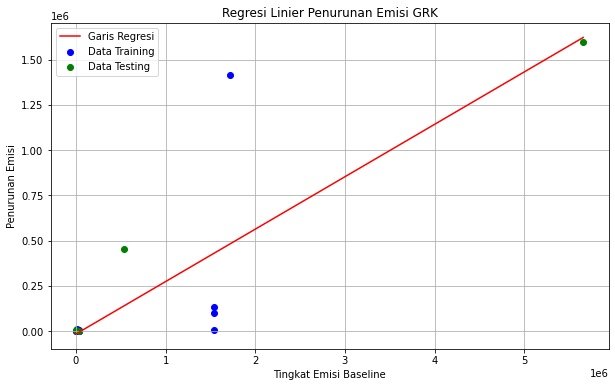

In [9]:
# Membuat visualisasi regresi linier

plt.figure(figsize=(10, 6))

# Menampilkan data training
plt.scatter(
    X_train['tingkat_emisi_baseline'],
    y_train,
    color='blue',
    label='Data Training'
)

# Menampilkan data testing
plt.scatter(
    X_test['tingkat_emisi_baseline'],
    y_test,
    color='green',
    label='Data Testing'
)

# Membuat garis regresi
x_garis = pd.DataFrame({
    'tingkat_emisi_baseline': np.linspace(
        X['tingkat_emisi_baseline'].min(),
        X['tingkat_emisi_baseline'].max(),
        100
    )
})

y_garis = model.predict(x_garis)

plt.plot(
    x_garis['tingkat_emisi_baseline'],
    y_garis,
    color='red',
    label='Garis Regresi'
)

plt.title('Regresi Linier Penurunan Emisi GRK')
plt.xlabel('Tingkat Emisi Baseline')
plt.ylabel('Penurunan Emisi')
plt.legend()
plt.grid(True)

plt.show()

In [10]:
# Menyimpan hasil prediksi ke file CSV

hasil_prediksi.to_csv(
    'hasil_prediksi_regresi_linier.csv',
    index=False
)

print("Hasil prediksi berhasil disimpan!")

Hasil prediksi berhasil disimpan!
